# 01. 탐색적 데이터 분석 (EDA)
담당: 데이터 A · 함수는 `src/eda.py`, `src/visualize.py`에 있고 이 노트북은 결과를 보고 해석만 합니다.

각 섹션 아래 **인사이트** 칸에 발견한 점과 다음 행동(정제·증강·모델 실험)을 적어 주세요. 보고서에 그대로 옮깁니다.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.utils import load_config
from src.visualize import set_korean_font

set_korean_font()
pd.set_option("display.max_columns", 50)

CONFIG = "configs/base.yaml"  # 샘플 데이터로 연습: "configs/sample_yolo.yaml"
cfg = load_config(CONFIG)
d = cfg["data"]

## 1. 데이터 읽기

In [2]:
from src.dataset import build_class_map, load_records
from src.eda import dataset_summary, records_to_frames

records, categories = load_records(d["train_annotations"])
class_map = build_class_map(records, categories)
images_df, boxes_df = records_to_frames(records, class_map)
dataset_summary(images_df, boxes_df)

이미지 수              232.00
박스 수               763.00
클래스 수               56.00
이미지당 평균 알약 수         3.29
클래스당 박스 수 (최소)       3.00
클래스당 박스 수 (중앙값)      9.00
클래스당 박스 수 (최대)     153.00
이미지 크기 종류            1.00
dtype: float64

## 2. 클래스 분포
클래스마다 박스 수가 얼마나 다른가? 아주 적은 클래스는 증강·외부 데이터 보강 후보입니다.

/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 48149 (\N{HANGUL SYLLABLE BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:128: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu

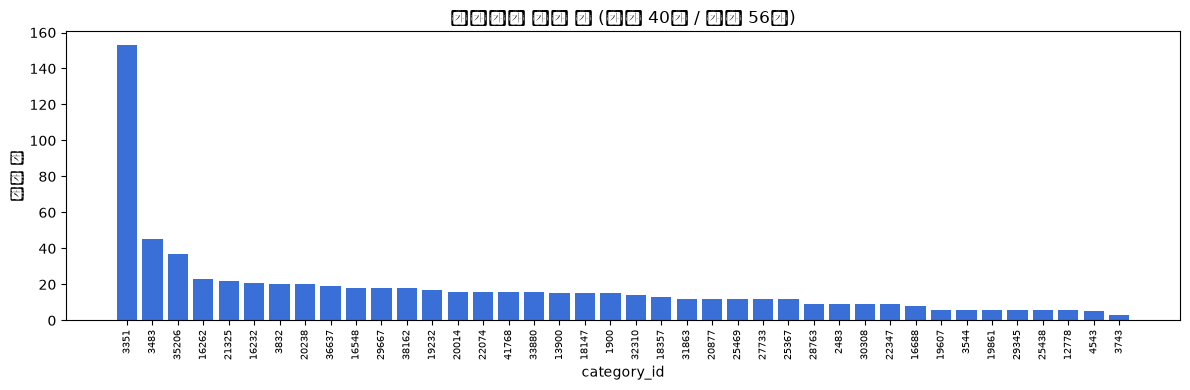

,category_id,name,n_boxes,n_images,share_%
0,3351,일양하이트린정 2mg,153,153,20.05
1,3483,기넥신에프정(은행엽엑스)(수출용),45,45,5.90
2,35206,아토젯정 10/40mg,37,37,4.85
3,16262,크레스토정 20mg,23,23,3.01
4,21325,아토르바정 10mg,22,22,2.88
5,16232,리피토정 20mg,21,21,2.75
6,3832,뉴로메드정(옥시라세탐),20,20,2.62
7,20238,플라빅스정 75mg,20,20,2.62
8,36637,로수젯정10/5밀리그램,19,19,2.49
9,16548,가바토파정 100mg,18,18,2.36


In [3]:
from src.eda import class_distribution
from src.visualize import plot_class_distribution

class_df = class_distribution(boxes_df)
plot_class_distribution(class_df)
class_df.head(10)

In [4]:
class_df.tail(10)  # 가장 적은 클래스

,category_id,name,n_boxes,n_images,share_%
46,21771,라비에트정 20mg,3,3,0.39
47,24850,놀텍정 10mg,3,3,0.39
48,27993,졸로푸트정 100mg,3,3,0.39
49,27926,울트라셋이알서방정,3,3,0.39
50,27777,카나브정 60mg,3,3,0.39
51,29451,레일라정,3,3,0.39
52,31885,자누메트엑스알서방정 100/1000mg,3,3,0.39
53,34597,제미메트서방정 50/1000mg,3,3,0.39
54,33009,신바로정,3,3,0.39
55,33208,에스원엠프정 20mg,3,3,0.39


**인사이트:** 

## 3. 이미지 크기와 이미지당 알약 수

In [5]:
from src.eda import image_size_stats, objects_per_image

display(image_size_stats(images_df))
objects_per_image(images_df)

,width,height,n_images
0,976,1280,232


,n_objects,n_images
0,2,7
1,3,151
2,4,74


**인사이트:** 

## 4. 박스 크기·비율·위치
알약이 작으면 입력 해상도를 키우는 실험(D6), 위치가 몰려 있으면 이동·크롭 증강의 근거가 됩니다.

,count,mean,std,min,5%,25%,50%,75%,95%,max
box_w,763.0,250.008,73.772,125.000,180.000,189.500,230.000,285.000,408.800,529.000
box_h,763.0,265.764,95.653,126.000,181.000,191.000,227.000,316.000,451.000,664.000
area,763.0,70384.793,42608.637,23250.000,33485.300,36672.000,53600.000,93492.500,155420.800,272435.000
aspect,763.0,0.992,0.269,0.396,0.589,0.829,1.000,1.041,1.543,2.108
rel_area,763.0,0.056,0.034,0.019,0.027,0.029,0.043,0.075,0.124,0.218


/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.


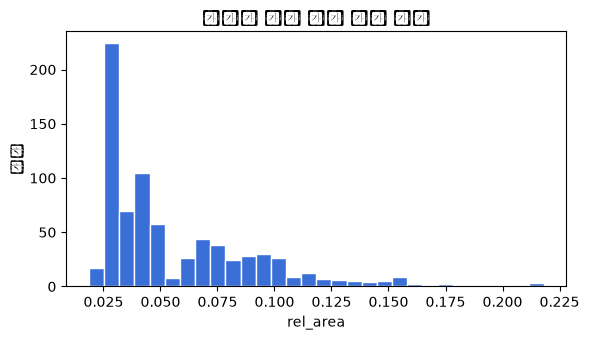

/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chung/pill_detection_project/YacssoK/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chung/pill_d

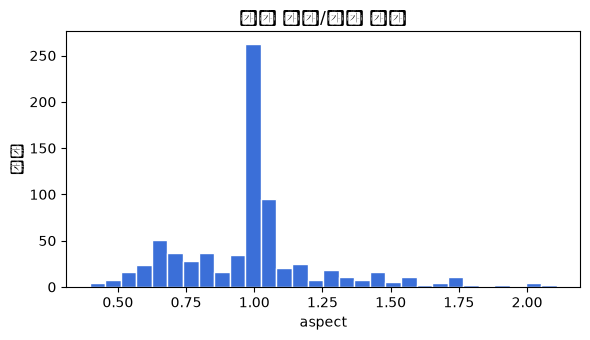

/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 48149 (\N{HANGUL SYLLABLE BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 49900 (\N{HANGUL SYLLABLE SIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:149: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sa

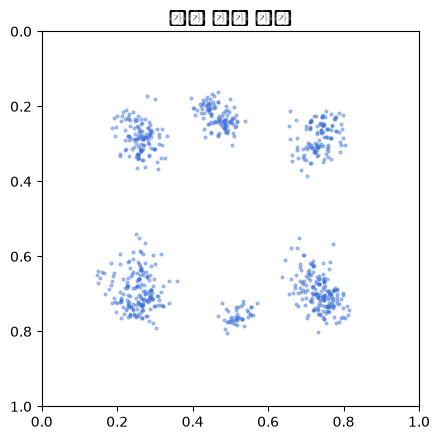

In [6]:
from src.eda import bbox_stats
from src.visualize import plot_box_centers, plot_hist

display(bbox_stats(boxes_df))
plot_hist(boxes_df["rel_area"], "이미지 대비 박스 면적 비율", xlabel="rel_area")
plot_hist(boxes_df["aspect"], "박스 가로/세로 비율", xlabel="aspect")
plot_box_centers(boxes_df)

,category_id,name,n_boxes,mean_w,mean_h,mean_rel_area
0,19607,스토가정 10mg,6,158.667,154.167,0.020
1,1900,보령부스파정 5mg,15,169.467,176.133,0.023
2,12247,아빌리파이정 10mg,3,178.000,188.333,0.027
3,3351,일양하이트린정 2mg,153,186.196,187.562,0.028
4,27777,카나브정 60mg,3,177.000,199.667,0.028
5,22074,리피로우정 20mg,16,186.562,190.188,0.028
6,21771,라비에트정 20mg,3,192.000,185.667,0.029
7,16232,리피토정 20mg,21,193.571,188.857,0.029
8,19861,노바스크정 5mg,6,222.667,172.000,0.031
9,21325,아토르바정 10mg,22,182.045,217.636,0.031


/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chung/pill_detection_project/YacssoK/src/visualize.py:138: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu

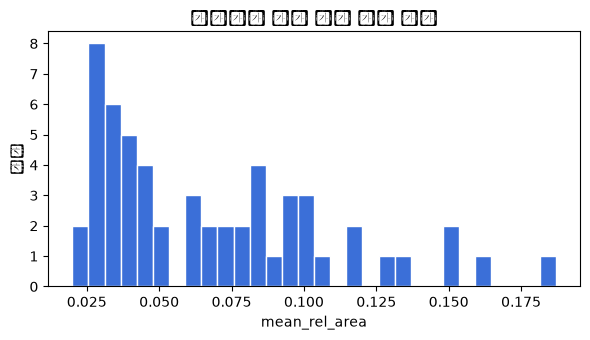

In [7]:
from src.eda import class_box_size

size_df = class_box_size(boxes_df)
display(size_df.head(10))  # 가장 작은 알약 10종
plot_hist(size_df["mean_rel_area"], "클래스별 평균 박스 면적 비율", xlabel="mean_rel_area")

**인사이트:** 

## 촬영 배경별 이미지 수
배경 편향 여부를 확인합니다. 
예를 들어, B정이 거의 검은색 배경에서 찍힌 이미지 뿐이라면, 모델은 검은색 배경을 보면 B정일 확률이 높다고 예측할 수 있음

In [11]:
from src.eda import background_counts
background_counts(d["train_annotations"])

,index,n_images
0,연회색 배경,232


**인사이트: 실제 이미지를 보면 배경색이 다름. json 메타데이터 품질이 의심스러움. back_color 기반 EDA는 신뢰할 수 없으므로 일단 분석 대상에서 제외하기로**

## 5. 라벨 오류 의심 항목
대회 안내: 제공 데이터에 크고 작은 오류가 있습니다. 결과를 데이터 B에게 넘겨 정제(v1)에 반영합니다.

In [8]:
from src.eda import find_label_issues

issues = find_label_issues(images_df, boxes_df, image_dir=d["train_images"])
display(issues["issue"].value_counts())
issues.head(20)

issue
heavy_overlap    3
out_of_bounds    1
Name: count, dtype: int64

,file_name,issue,category_id
0,K-003351-016262-018357_0_2_0_2_75_000_200.png,out_of_bounds,18357.0
1,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,heavy_overlap,NaN
2,K-003351-020238-031863_0_2_0_2_70_000_200.png,heavy_overlap,NaN
3,K-003351-029667-031863_0_2_0_2_70_000_200.png,heavy_overlap,NaN


**인사이트:** 

## 6. 샘플 이미지

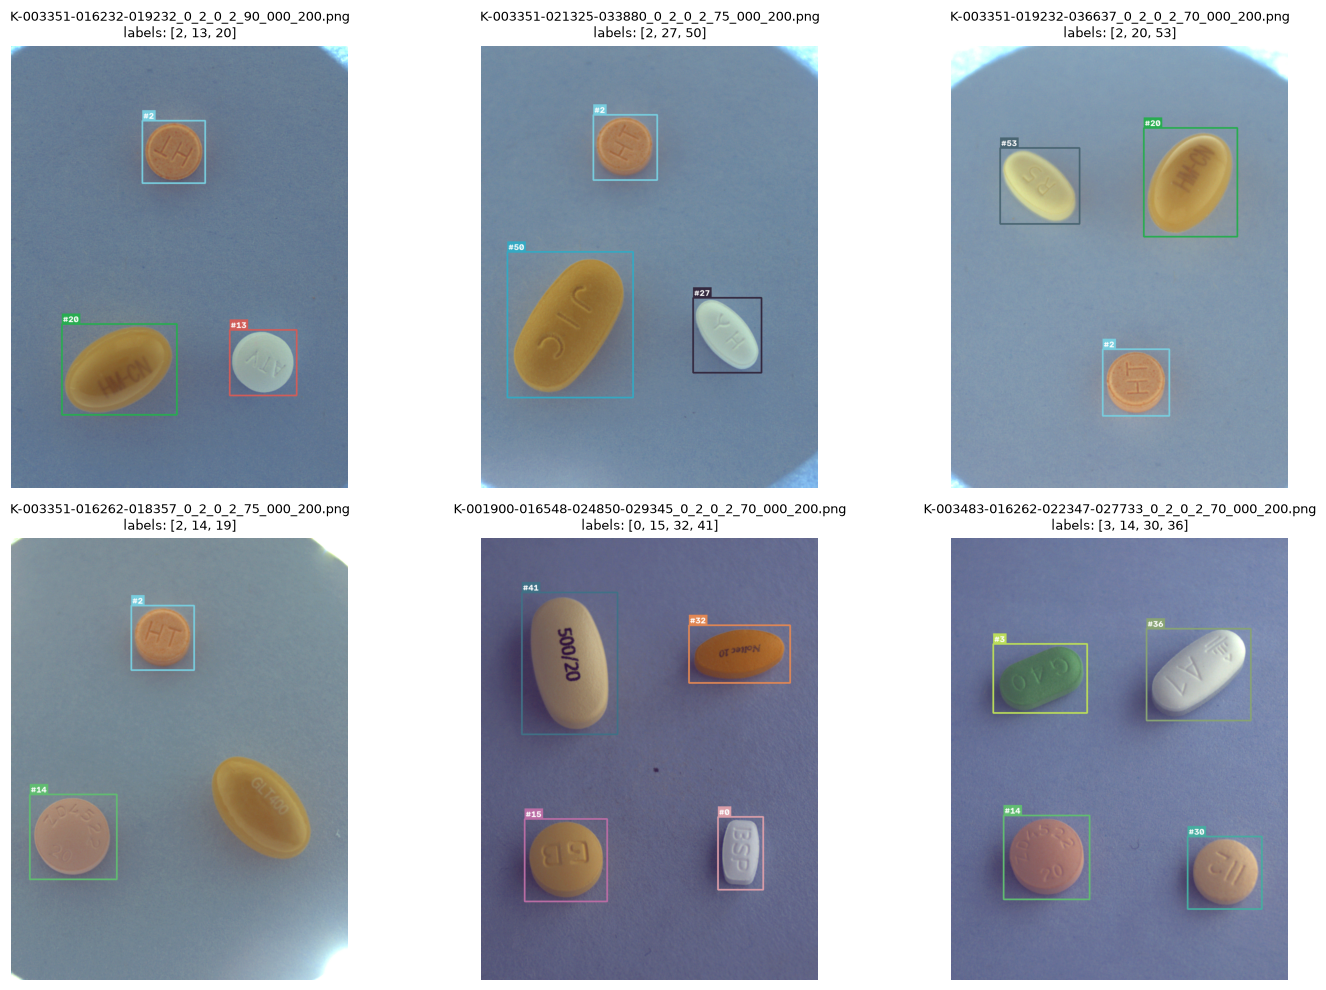

In [9]:
from src.visualize import show_samples

show_samples(records, d["train_images"], class_map, n=6)

## 7. 테스트 이미지 확인
테스트에는 학습에 없는 클래스가 있습니다(대회 안내). 테스트 이미지 몇 장을 보고 학습 이미지와 촬영 조건이 비슷한지 봅니다.

테스트 이미지 842장


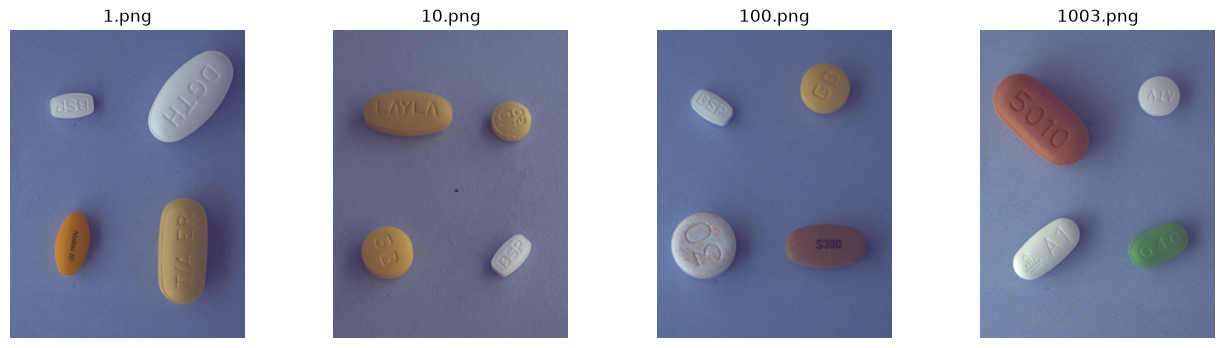

In [10]:
import matplotlib.pyplot as plt

from src.dataset import list_images, read_image_rgb

test_paths = list_images(d["test_images"])
print(f"테스트 이미지 {len(test_paths)}장")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, p in zip(axes, test_paths[:4]):
    ax.imshow(read_image_rgb(p))
    ax.set_title(p.name)
    ax.axis("off")
plt.show()

## 정리
- 핵심 발견 3가지:
- 정제(데이터 B)에 넘길 항목:
- 실험 제안(모델 A·B):